## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leann Vo

**Date:** 10/13/2026

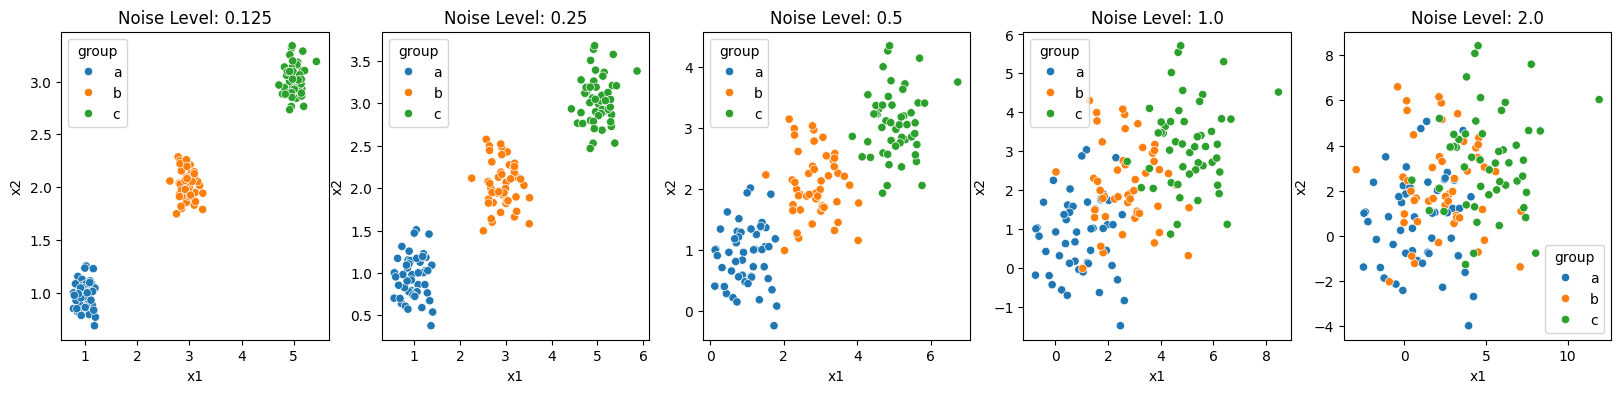

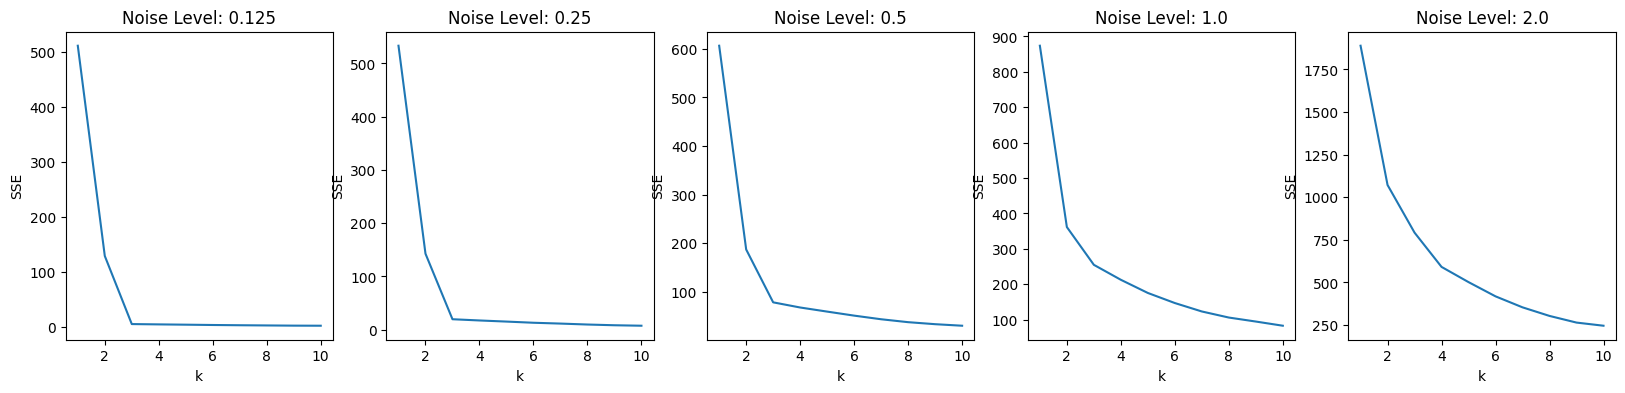

In [6]:
# Question 1: which creates four datasets: df0_125, df0_25, df0_5, df1_0, and df2_0.
# Each data set is created by increasing the amount of noise (standard deviation) around
# the cluster centers, from 0.125 to 0.25 to 0.5 to 1.0 to 2.0.

# 1.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# 2a/2b. Scatterplots of the (X1, X2) points by group for each of the datasets.
import matplotlib.pyplot as plt
import seaborn as sns

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noiselvls = [0.125, 0.25, 0.5, 1.0, 2.0]

fig, axs = plt.subplots(1, 5, figsize=(20, 4)) #1 fig. with 5 horizontal plots for datasets

for i in range(5):
  sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group", ax=axs[i])
  axs[i].set_title(f'Noise Level: {noiselvls[i]}') #loop to make each scatterplot

plt.show()


# 2c. As the noise goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
## As noise increases from 0.125 to 2.0, the points in each cluster become more spread out and the clusters overlap more with each other.


# 3a/3b. Create a scree plot for each of the datasets.
from sklearn.cluster import KMeans

ks = np.arange(1,11)
fig, axs = plt.subplots(1, 5, figsize=(20, 4))
for i in range(5):
  X = datasets[i][["x1","x2"]]
  SSE = [
      KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
      for k in ks
  ]

  sns.lineplot(x=ks, y=SSE, ax=axs[i])
  axs[i].set_title(f'Noise Level: {noiselvls[i]}')
  axs[i].set_xlabel('k')
  axs[i].set_ylabel('SSE')

plt.show()


# 3c and 3d. Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a 𝑘 .
# (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
## At lower noise levels (0.125, 0.25, and 0.50), there is a clear "elbow" at k=3 where the SSE begins to level out. As noise increases to 1.0 and 2.0,
## the "elbow" is less distinct and harder to make out because the SSE decreases more gradually. This makes it harder to confidently select an optimal k
## at higher noise levels (1.0 and 2.0). Higher noise levels also have larger overall SSE values as seen on the vertical axis.


# 4a/4b. Explain the intuition of the elbow, using this numerical simulation as an example.
## The elbow represents the point where increasing the k will make much smaller reductions in SSE. In this numerical simulation, the elbow is clear at k=3 for
## the lower noise levels because the data contains three distinct groups (a,b,c). Using less than 3 clusters would combine separate groups while using more
## than 3 will give us little additional improvement. We also know that as noise increases, the clusters will overlap more which makes the elbow less distinct
## and the optimal k harder to determine.

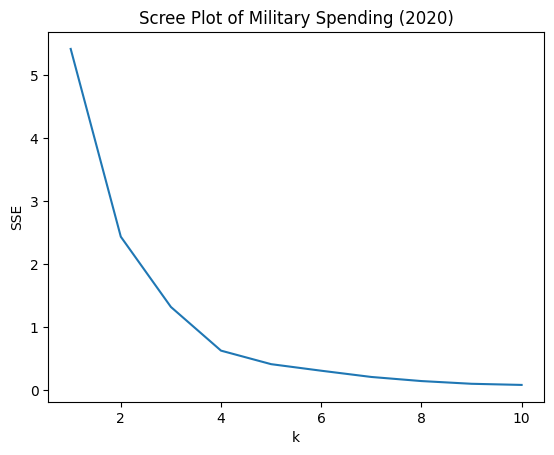

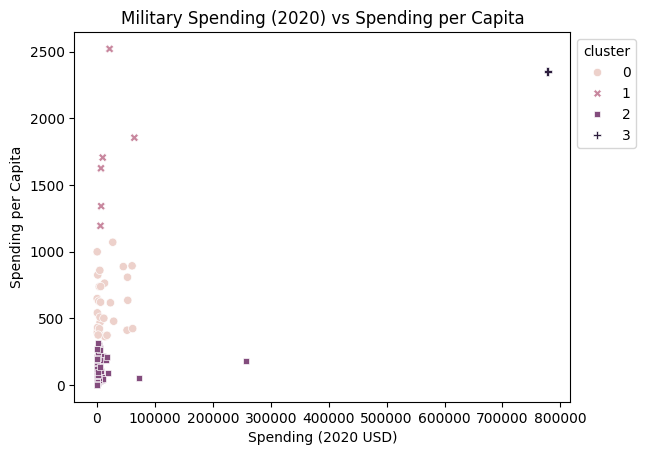

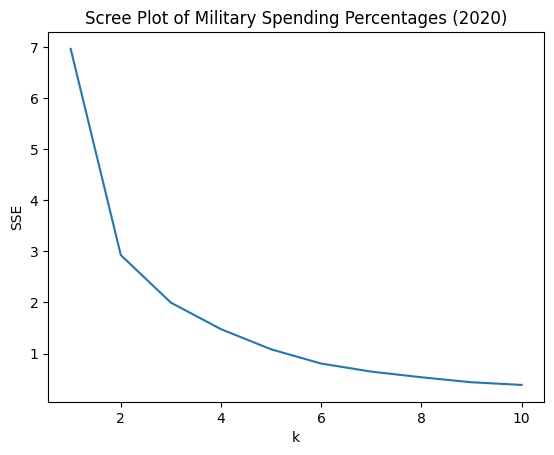

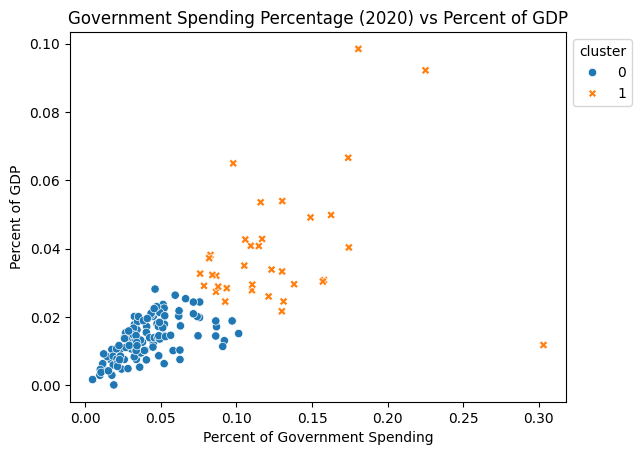

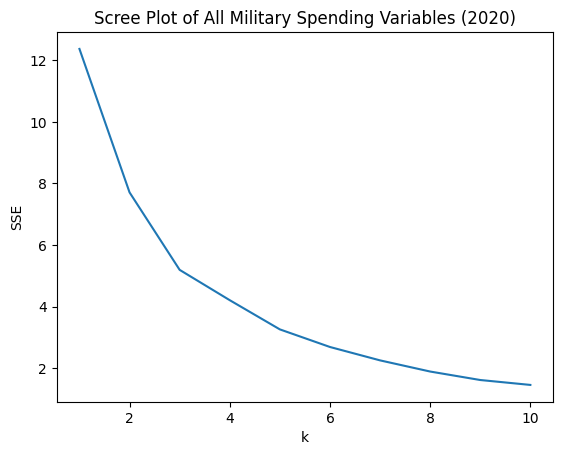

,Country,cluster
5540,United States of America,2


In [36]:
# Question 2:

# 1a. Load the SIPRI Military Expenditure Database.csv file in the ./data folder. This has data about military spending by country.
df = pd.read_csv('./SIPRI Military Expenditure Database.csv')


# 1a cont. Filter the rows to select only the year 2020, and drop all rows with missing values.
df = df[df['Year'] == 2020]
df = df.dropna()

# df.head()
# df.shape # (148, 7)
# df.info()

# 1b. I ended up with 148 countries. Is any further cleaning of the variables required?
## No additional cleaning is needed. After filtering for the year 2020 and dropping missing values, 148 countries remained. All 4 spending
## variables (Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP) were already numerical (float64).


# 2a. Max-min normalize Spending (2020 USD) and Spending per Capita.
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min', 'max'])


# 2b. Use a scree plot to determine the optimal number of clusters for the  𝑘  means clustering algorithm.
ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title = 'Scree Plot of Military Spending (2020)',
    xlabel = 'k',
    ylabel = 'SSE'
)

plt.show()

## Based on the scree plot for miltary spending in 2020, the optimal k is 4 because the SSE decreases rapidly until k = 4 and then begins to level out.
## If we added more than 4 clusters, there would be smaller improvements in SSE.


# 2c. Make a scatter plot of Spending (2020 USD) and Spending per Capita, and hue the dots by their cluster membership.
model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

ax = sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", style="cluster")
plt.title('Military Spending (2020) vs Spending per Capita')
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1,1))
plt.show()


# 2d. Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()).
df.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
  ]].describe()


# 2e. What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

df.loc[df['Country']=='United States of America', ['Country', 'cluster']]
## Most countries (111) are grouped into cluster 2 which for the most part, has a low total spending and spending per capita. Cluster 0 has 30 countries
## a higher spending per capita, while cluster 1 has 6 countries with a rather high spending per capita. The US is the only country in cluster 3 due to
## its very high total military spending. Overall, the clusters aren't evenly distributed and there are a few high-spending countries that are standing
## apart from the rest.


# 3a. Max-min normalize Percent of Government Spending and Percent of GDP.
features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min', 'max'])


# 3b. Use a scree plot to determine the optimal number of clusters for the  𝑘  means clustering algorithm.
ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title = 'Scree Plot of Military Spending Percentages (2020)',
    xlabel = 'k',
    ylabel = 'SSE'
)

plt.show()

## Based on the scree plot for military spending percentages in 2020, k=2 seems like the optimal number of clusters because SSE decreased sharply from k=1 to k=2,
## then began to decrease more gradually. While k=3 could also be reasonable, the largest reduction in SSE occurs at k=2 so I think it is the stronger choice
## based on the elbow method.


# 3c. Make a scatter plot of Percent of Government Spending and Percent of GDP, and hue the dots by their cluster membership.
model = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

ax = sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", style="cluster")
plt.title('Government Spending Percentage (2020) vs Percent of GDP')
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1,1))
plt.show()


# 3d. Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()).
df.groupby('cluster')[[
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
  ]].describe()


# 3e. What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
df.loc[df['Country']=='United States of America', ['Country', 'cluster', 'Percent of Government Spending', 'Percent of GDP']]
## Cluster 0 has 113 countries that generally seem to give smaller percentages of government spending and GDP to the military. Cluster 1 has 35 countries
## with higher military spending percentages. The US is in cluster 1 and it allocates about 8.20$ of government spending and 3.72% of GDP to the military.
## Overall, the clusters distinguish countries based on the proportion of resources given to defense rather than just the total amount spent.


# 3f. How do your results compare to part 2?
## Part 2 had 4 uneven clusters based on total military spending and spending per capita with the US having its own cluster. Part 3 had two larger clusters
## based on spending as a percentage of government spending and GDP. The US was grouped with 34 other countries in part 3 which shows that while its total
## military spending is abnormally high, its spending relative to government budgets and GDP is more comparable to other countries.


# 4a/4b. Use  𝑘  means clustering with all four numeric variables:
# Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP.
features = ['Spending (2020 USD)',
            'Spending per Capita',
            'Percent of Government Spending',
            'Percent of GDP']
unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min', 'max'])

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title = 'Scree Plot of All Military Spending Variables (2020)',
    xlabel = 'k',
    ylabel = 'SSE'
)

plt.show()

## Based on the scree plot, k=3 seems like the most reasonable number of clusters. Although k=5 could also be considered, k=3 captures more of the reduction
## in SSE while using fewer clusters.

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

df.groupby('cluster').size()
df.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].describe()
df.loc[df['Country']=='United States of America', ['Country', 'cluster',]]

## Using all 4 spending variables with k=3 made 3 uneven clusters containing 111, 31, and 6 countries. Cluster 0 generally had the lowest military spending
## cluster 1 had higher spending percentages but similar average total spending. Cluster 2 had way higher average total spending, spending per capita, and
## percentage of GDP. The US is in cluster 2 with 5 other countries.


# 4c. How do your results compare to the previous two parts?
## Using all 4 variables made 3 clusters compared to 4 in part 2 and 2 in part 3. In part 2, the US formed its own cluster while in part 3, it was grouped
## with 34 other countries. Using all 4 variables placed the US in a smaller cluster of 6 countries with relatively high military spending. This shows
## that combining absolute and relative spending measures creates different groupings and gives us a more comprehensive view of military spending patterns.


# 5. Did the 𝑘 -MC algorithm find any useful patterns for you in analyzing the spending?
## Yes, k-means clustering revealed useful patterns in military spending by distinguishing countries based on both absolute spending and the proportion of
## resources devoted to the military. The US stood out when we are considering total spending but became more comparable to other countries when using
## percentage-based measures. Combining all 4 variables identified a small group of high-spending countries. Overall, the results showed that cluster
## membership depends on which variables are being considered and no single measure can fully capture military spending patterns.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [3]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]